### NLP Lab 4

In [1]:
import re, time
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import nltk, spacy
from nltk.corpus import stopwords, movie_reviews, brown
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.tokenize import sent_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline

for pkg in ["stopwords", "movie_reviews", "brown", "punkt_tab", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)
nlp = spacy.load("en_core_web_sm")      # python -m spacy download en_core_web_sm
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

## Task 1: Lowercasing and its drawbacks
(a) Build a small corpus with the same word in different cases. (b) Compare the vocabulary before and after lowercasing.
(c) Give three examples where lowercasing creates confusion. (d) Name NLP tasks that suffer.

**(a, b)** Corpus and vocabulary size

In [2]:
corpus = [
    "Apple released a new phone while I ate an apple.",
    "Bill Gates paid the electricity bill.",
    "The US government asked us to wait.",
    "Turkey is famous for kebabs, not for turkey sandwiches.",
    "Python is easy to learn, but a python is hard to catch.",
    "WHO says people who smoke are at risk.",
    "Mark Twain left a mark on literature.",
    "The Jaguar was faster than a jaguar in the forest.",
    "March is cold, so we march to work in coats.",
    "Polish food is nice, but I must polish my shoes.",
    "Will Smith said he will arrive tomorrow.",
    "I booked a flight to Nice, and the weather was nice.",
]
words = [w for s in corpus for w in re.findall(r"[A-Za-z']+", s)]
vocab_before = set(words)
vocab_after = {w.lower() for w in words}
print("Total words      :", len(words))
print("Vocabulary before:", len(vocab_before))
print("Vocabulary after :", len(vocab_after))

merged = defaultdict(set)
for w in vocab_before:
    merged[w.lower()].add(w)
merged = {k: sorted(v) for k, v in merged.items() if len(v) > 1}
print("\nWords that were merged:")
for k, v in sorted(merged.items()):
    print(f"  {k:<8}<- {v}")

Total words      : 107
Vocabulary before: 85
Vocabulary after : 72

Words that were merged:
  apple   <- ['Apple', 'apple']
  bill    <- ['Bill', 'bill']
  jaguar  <- ['Jaguar', 'jaguar']
  march   <- ['March', 'march']
  mark    <- ['Mark', 'mark']
  nice    <- ['Nice', 'nice']
  polish  <- ['Polish', 'polish']
  python  <- ['Python', 'python']
  the     <- ['The', 'the']
  turkey  <- ['Turkey', 'turkey']
  us      <- ['US', 'us']
  who     <- ['WHO', 'who']
  will    <- ['Will', 'will']


**Observation:** the 12 sentences contain 107 words. The vocabulary falls from 85 to 72 after lowercasing, so 13 words were merged. Some merges are harmless (*The / the*), but others join different meanings: *Apple / apple*, *Bill / bill*, *Python / python*, *Turkey / turkey*, *US / us* and *WHO / who*.

**(c)** Three confusing examples

In [3]:
for i in (1, 4, 10):
    s = corpus[i]
    lower_words = [w.lower() for w in re.findall(r"[A-Za-z']+", s)]
    clash = [k for k in merged if k in lower_words and k != "the"]
    print("Original :", s)
    print("Lowercase:", s.lower())
    print("Now identical:", clash, "\n")

Original : Bill Gates paid the electricity bill.
Lowercase: bill gates paid the electricity bill.
Now identical: ['bill'] 

Original : Python is easy to learn, but a python is hard to catch.
Lowercase: python is easy to learn, but a python is hard to catch.
Now identical: ['python'] 

Original : Will Smith said he will arrive tomorrow.
Lowercase: will smith said he will arrive tomorrow.
Now identical: ['will'] 



**Observation:** in each example the capital letter was the only clue that separated a name or abbreviation from a common word (*Bill Gates* and *bill*, *Python* and *python*, *Will Smith* and *will*). After lowercasing a model sees one word with several meanings.

**(d)** NLP tasks harmed by lowercasing

- **Named Entity Recognition:** a capital letter is the strongest hint that a word is a name. After lowercasing, *Apple* (company), *Bill* (person) and *Turkey* (country) look like ordinary words.
- **Sentiment analysis:** all caps such as *GREAT* or *TERRIBLE* shows strong feeling, and lowercasing removes that intensity. It also confuses names with sentiment words, for example *Will* and *will*.
- **Search:** a query for *Python* (the language) and one for *python* (the snake) become the same query, so the engine returns mixed results. *US* and *us* are merged in the same way.

## Task 2: Noise removal pipeline
(a) Make a noisy dataset. (b) Write one regex function per noise type. (c) Combine them in `clean_text` and test the order. (d) Show examples and find over-cleaning.

**(a)** Noisy dataset

In [4]:
noisy = [
    "OMG!!! check this out https://t.co/abc123 😍😍 #blessed",
    "@john_doe thanks for the help!!   see you at 5pm",
    "<p>Great <b>product</b>, works as expected.</p>",
    "Learning C++ and Python is fun #coding #100DaysOfCode",
    "Only $100 for this phone!!! visit www.deals.com now",
    "Email me at sara.khan@example.com for details",
    "The R&D team worked 3.5 hours on the bug 🐛",
    "<div>Price dropped to $49.99</div>   hurry up",
    "@alice @bob Who's coming to the party tonight??",
    "Best    pizza    in   town!!! 🍕 #foodie",
    "I'm so happy :) it's 24/7 support",
    "Visit https://example.com/page?id=5 for more info",
    "<a href='x'>click</a> to win #giveaway @shop",
    "Wi-Fi is down again... call 0300-1234567",
    "Mr. Ahmed's co-op got 20% off on all items!!!",
]
print(len(noisy), "texts")
for t in noisy[:3]:
    print(" ", t)

15 texts
  OMG!!! check this out https://t.co/abc123 😍😍 #blessed
  @john_doe thanks for the help!!   see you at 5pm
  <p>Great <b>product</b>, works as expected.</p>


**(b)** One function per noise type

In [5]:
def remove_html(t):        return re.sub(r"<[^>]+>", " ", t)
def remove_urls(t):        return re.sub(r"(https?://|www\.)\S+", "", t)
def remove_mentions(t):    return re.sub(r"@\w+", "", t)
def keep_hashtag_word(t):  return re.sub(r"#(\w+)", r"\1", t)
def remove_emojis(t):      return re.sub(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", "", t)
def remove_punct(t):       return re.sub(r"[^\w\s]", "", t)
def fix_spaces(t):         return re.sub(r"\s+", " ", t).strip()

demo = "<b>Hi</b> @sam see https://x.co #fun 😀 now!!   ok"
for f in (remove_html, remove_urls, remove_mentions, keep_hashtag_word, remove_emojis, remove_punct, fix_spaces):
    print(f"{f.__name__:<18}{f(demo)!r}")

remove_html       ' Hi  @sam see https://x.co #fun 😀 now!!   ok'
remove_urls       '<b>Hi</b> @sam see  #fun 😀 now!!   ok'
remove_mentions   '<b>Hi</b>  see https://x.co #fun 😀 now!!   ok'
keep_hashtag_word '<b>Hi</b> @sam see https://x.co fun 😀 now!!   ok'
remove_emojis     '<b>Hi</b> @sam see https://x.co #fun  now!!   ok'
remove_punct      'bHib sam see httpsxco fun  now   ok'
fix_spaces        '<b>Hi</b> @sam see https://x.co #fun 😀 now!! ok'


**(c)** `clean_text` and the effect of order

In [6]:
normal  = [remove_html, remove_urls, remove_mentions, keep_hashtag_word, remove_emojis, remove_punct, fix_spaces]
punct_1 = [remove_punct] + [f for f in normal if f is not remove_punct]
space_1 = [fix_spaces] + [f for f in normal if f is not fix_spaces]

def clean_text(text, steps=normal):
    for step in steps:
        text = step(text)
    return text

base = [clean_text(t, normal) for t in noisy]
for name, steps in [("punctuation first", punct_1), ("whitespace first", space_1)]:
    out = [clean_text(t, steps) for t in noisy]
    changed = [i for i in range(len(noisy)) if out[i] != base[i]]
    print(f"{name}: {len(changed)} of {len(noisy)} outputs differ")
    for i in changed[:3]:
        print("   normal :", base[i])
        print("   changed:", out[i])

punctuation first: 9 of 15 outputs differ
   normal : OMG check this out blessed
   changed: OMG check this out httpstcoabc123 blessed
   normal : thanks for the help see you at 5pm
   changed: john_doe thanks for the help see you at 5pm
   normal : Great product works as expected
   changed: pGreat bproductb works as expectedp
whitespace first: 11 of 15 outputs differ
   normal : OMG check this out blessed
   changed: OMG check this out   blessed
   normal : thanks for the help see you at 5pm
   changed:  thanks for the help see you at 5pm
   normal : Great product works as expected
   changed:  Great  product  works as expected 


**Observation:** the order matters. Removing punctuation first breaks the URL (`httpstcoabc123` stays), turns `@john_doe` into a normal word and leaves tag letters stuck to words (`pGreat`). Normalizing whitespace first leaves new double spaces behind, so it must be the last step. The order used in `normal` removes structured noise first (HTML, URLs, mentions) and punctuation after that.

**(d)** Before and after table, and over-cleaning check

In [7]:
rows = [3, 4, 5, 6, 14]
print(pd.DataFrame({"Before": [noisy[i] for i in rows], "After": [base[i] for i in rows]}).to_string())

print()
for item in ["C++", "$100", "sara.khan@example.com", "R&D", "3.5", "$49.99", "24/7", "Wi-Fi", "20%"]:
    for i, t in enumerate(noisy):
        if item in t:
            print(f"{item:<22}", "kept" if item in base[i] else "LOST ->", base[i] if item not in base[i] else "")

                                                  Before                                              After
0  Learning C++ and Python is fun #coding #100DaysOfCode  Learning C and Python is fun coding 100DaysOfCode
1    Only $100 for this phone!!! visit www.deals.com now                  Only 100 for this phone visit now
2          Email me at sara.khan@example.com for details                Email me at sarakhancom for details
3             The R&D team worked 3.5 hours on the bug 🐛             The RD team worked 35 hours on the bug
4          Mr. Ahmed's co-op got 20% off on all items!!!             Mr Ahmeds coop got 20 off on all items

C++                    LOST -> Learning C and Python is fun coding 100DaysOfCode
$100                   LOST -> Only 100 for this phone visit now
sara.khan@example.com  LOST -> Email me at sarakhancom for details
R&D                    LOST -> The RD team worked 35 hours on the bug
3.5                    LOST -> The RD team worked 35 hours on the bu

**Observation:** every special item was lost: `C++` became `C`, `$100` lost its currency sign, the e-mail address was broken, `R&D` became `RD`, `3.5` became `35` and `24/7` became `247`. This is over-cleaning, because the punctuation step cannot tell useful symbols from noise. A fix is to protect e-mails, prices and numbers before removing punctuation, or to remove only a chosen list of symbols.

## Task 3: Stop word removal
(a) Load NLTK stop words. (b) Compare a movie-review dataset before and after removal. (c) Plot the top 15 words. (d) Build a custom stop word list.

**(a)** NLTK English stop words

In [8]:
stop_list = stopwords.words("english")
stop_set = set(stop_list)
print("Size:", len(stop_list))
print(stop_list[:20])

Size: 198
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


**(b)** 500 reviews (250 negative, 250 positive): tokens, vocabulary and sentence length

In [9]:
ids = movie_reviews.fileids("neg")[:250] + movie_reviews.fileids("pos")[:250]
sents = [s for i in ids for s in sent_tokenize(movie_reviews.raw(i))]
sent_tokens = [re.findall(r"[a-z']+", s.lower()) for s in sents]
sent_clean  = [[w for w in toks if w not in stop_set] for toks in sent_tokens]

def stats(token_lists):
    flat = [w for toks in token_lists for w in toks]
    return len(flat), len(set(flat)), round(len(flat) / len(token_lists), 2)

table = pd.DataFrame([stats(sent_tokens), stats(sent_clean)],
                     index=["Before", "After"],
                     columns=["Total tokens", "Vocabulary", "Avg sentence length"])
print(len(sents), "sentences")
print(table)

17081 sentences
        Total tokens  Vocabulary  Avg sentence length
Before        310188       22719                18.16
After         168914       22535                 9.89


**Observation:** stop word removal cuts the tokens from 310,188 to 168,914 (about 46%) and the average sentence length from 18.16 to 9.89, but the vocabulary only falls from 22,719 to 22,535. There are few stop words, but they are very frequent.

**(c)** Top 15 words before and after removal

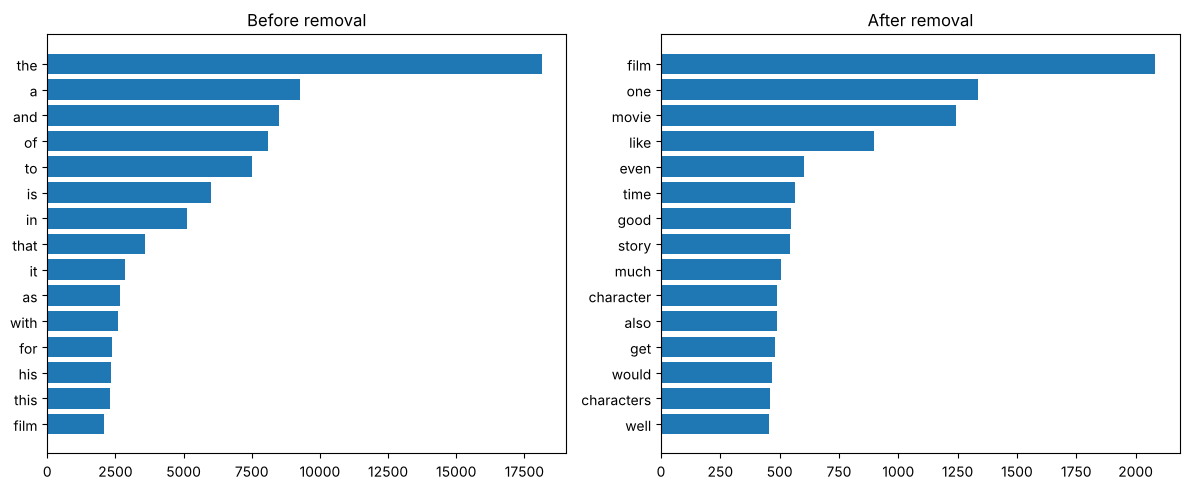

In [10]:
before = Counter(w for toks in sent_tokens for w in toks).most_common(15)
after  = Counter(w for toks in sent_clean  for w in toks).most_common(15)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, data, title in [(ax[0], before, "Before removal"), (ax[1], after, "After removal")]:
    a.barh([w for w, _ in data][::-1], [c for _, c in data][::-1])
    a.set_title(title)
plt.tight_layout()
plt.show()

**Observation:** before removal the top words are only stop words (*the, a, and, of, to*). After removal the chart shows content words such as *film, one, movie, like, even, good*, which describe the data much better.

**(d)** Custom stop word list for movie reviews

In [11]:
add = {"movie": "in every review, no sentiment", "film": "same as movie", "one": "filler", "would": "filler",
       "even": "filler", "also": "filler", "get": "filler verb", "make": "filler verb",
       "see": "filler verb", "story": "topic word, not opinion", "character": "topic word, not opinion",
       "time": "topic word, not opinion"}
remove = {"not": "negation", "no": "negation", "nor": "negation", "very": "intensifier",
          "too": "intensifier", "but": "shows contrast", "against": "shows opposition",
          "only": "limits meaning", "don't": "negation", "didn't": "negation", "wasn't": "negation"}

custom_set = (stop_set | set(add)) - set(remove)
print("Custom list size:", len(custom_set), "(NLTK was", len(stop_set), ")")
print(pd.DataFrame({"Change": ["added"] * len(add) + ["removed"] * len(remove),
                    "Word": list(add) + list(remove),
                    "Reason": list(add.values()) + list(remove.values())}).to_string(index=False))

custom_tokens = [w for toks in sent_tokens for w in toks if w not in custom_set]
print("\nNew top 10:", Counter(custom_tokens).most_common(10))

Custom list size: 199 (NLTK was 198 )
 Change      Word                        Reason
  added     movie in every review, no sentiment
  added      film                 same as movie
  added       one                        filler
  added     would                        filler
  added      even                        filler
  added      also                        filler
  added       get                   filler verb
  added      make                   filler verb
  added       see                   filler verb
  added     story       topic word, not opinion
  added character       topic word, not opinion
  added      time       topic word, not opinion
removed       not                      negation
removed        no                      negation
removed       nor                      negation
removed      very                   intensifier
removed       too                   intensifier
removed       but                shows contrast
removed   against              shows opposition
re

## Task 4: Risks of stop word removal
(1) Negation and sentiment. (2) Machine translation. (3) Chatbot intent. (4) A safer strategy.

**(1)** Negation and sentiment (VADER)

In [12]:
sia = SentimentIntensityAnalyzer()

def label(text):
    c = sia.polarity_scores(text)["compound"]
    return "positive" if c > 0.05 else "negative" if c < -0.05 else "neutral"

def drop_stops(text, stops=stop_set):
    return " ".join(w for w in re.findall(r"[a-z']+", text.lower()) if w not in stops)

neg_sents = ["The film is not good.", "I do not like this song.", "This is not a bad idea.",
             "We have no complaints about the hotel.", "He was not happy with the result."]

for s in neg_sents:
    r = drop_stops(s)
    print(f"{s:<42}{label(s):<10}| {r!r:<24}{label(r)}")

The film is not good.                     negative  | 'film good'             positive
I do not like this song.                  negative  | 'like song'             positive
This is not a bad idea.                   positive  | 'bad idea'              negative
We have no complaints about the hotel.    negative  | 'complaints hotel'      negative
He was not happy with the result.         negative  | 'happy result'          positive


**Observation:** the sentiment label changed in 4 of 5 sentences. *The film is not good* becomes *film good* (positive), and *This is not a bad idea* becomes *bad idea* (negative). *not* is in the NLTK stop word list, so the negation is deleted and the sentiment flips.

**(2)** Machine translation to Urdu (saved translations, so the cell runs without internet)

In [13]:
mt_sents = ["We should not eat here.", "The doctor is not in the clinic today.", "Do not open the door for strangers."]
for s in mt_sents:
    print(s, "->", repr(drop_stops(s)))

We should not eat here. -> 'eat'
The doctor is not in the clinic today. -> 'doctor clinic today'
Do not open the door for strangers. -> 'open door strangers'


In [14]:
urdu = {
    "We should not eat here.": "ہمیں یہاں نہیں کھانا چاہیے۔",
    "eat": "کھاؤ",
    "The doctor is not in the clinic today.": "ڈاکٹر آج کلینک میں نہیں ہے۔",
    "doctor clinic today": "ڈاکٹر کلینک آج",
    "Do not open the door for strangers.": "اجنبیوں کے لیے دروازہ نہ کھولیں۔",
    "open door strangers": "دروازہ کھولو اجنبی",
}
for s in mt_sents:
    r = drop_stops(s)
    print(f"{s}\n   {urdu[s]}\n{r}\n   {urdu[r]}\n")

We should not eat here.
   ہمیں یہاں نہیں کھانا چاہیے۔
eat
   کھاؤ

The doctor is not in the clinic today.
   ڈاکٹر آج کلینک میں نہیں ہے۔
doctor clinic today
   ڈاکٹر کلینک آج

Do not open the door for strangers.
   اجنبیوں کے لیے دروازہ نہ کھولیں۔
open door strangers
   دروازہ کھولو اجنبی



**Observation:** removing *not* gives the opposite meaning in Urdu. *We should not eat here* becomes just *eat*, and *Do not open the door for strangers* becomes *open door strangers*, which sounds like an instruction to open the door. The grammar words are also lost, so the Urdu is no longer a complete sentence.

**(3)** Chatbot intent with a small rule-based detector

In [15]:
def detect_intent(q):
    w = set(re.findall(r"[a-z']+", q.lower()))
    neg = bool(w & {"not", "no", "never", "don't"})
    if "cancel" in w:  return "cancel_one_item" if neg else "cancel_everything"
    if "delete" in w:  return "keep_account" if neg else "delete_account"
    if "receive" in w: return "email_missing" if neg else "general_info"
    if "charged" in w: return "billing_issue"
    if "parcel" in w:  return "track_order"
    return "unknown"

queries = ["I want to cancel my order but not the subscription", "Please do not delete my account",
           "I did not receive the confirmation email", "Why was I charged twice this month", "Where is my parcel"]

for q in queries:
    r = drop_stops(q)
    a, b = detect_intent(q), detect_intent(r)
    print(f"{q}\n   {a:<17}| {r!r}\n   {b:<17}{'  <- CHANGED' if a != b else ''}")

I want to cancel my order but not the subscription
   cancel_one_item  | 'want cancel order subscription'
   cancel_everything  <- CHANGED
Please do not delete my account
   keep_account     | 'please delete account'
   delete_account     <- CHANGED
I did not receive the confirmation email
   email_missing    | 'receive confirmation email'
   general_info       <- CHANGED
Why was I charged twice this month
   billing_issue    | 'charged twice month'
   billing_issue    
Where is my parcel
   track_order      | 'parcel'
   track_order      


**Observation:** the intent changed in 3 of 5 queries. *cancel my order but not the subscription* became `cancel_everything`, and *do not delete my account* became `delete_account`, which could remove a user's account by mistake. Queries whose meaning sits in content words (*charged*, *parcel*) were not affected.

**(4)** Safe stop word strategy: keep negations, intensifiers and contrast words

In [16]:
keep = {"not", "no", "nor", "very", "too", "but", "against", "only"} | {w for w in stop_set if w.endswith("n't")}
safe_set = stop_set - keep
print("Safe list size:", len(safe_set), "| words kept in text:", len(keep))

print(f"\n{'Sentence':<42}{'Original':<10}{'NLTK list':<10}Safe list")
for s in neg_sents:
    print(f"{s:<42}{label(s):<10}{label(drop_stops(s)):<10}{label(drop_stops(s, safe_set))}")

print("\nChatbot with the safe list:")
for q in queries:
    print(f"  {detect_intent(q):<17}{detect_intent(drop_stops(q, safe_set)):<17}{q}")

Safe list size: 172 | words kept in text: 26

Sentence                                  Original  NLTK list Safe list
The film is not good.                     negative  positive  negative
I do not like this song.                  negative  positive  negative
This is not a bad idea.                   positive  negative  positive
We have no complaints about the hotel.    negative  negative  negative
He was not happy with the result.         negative  positive  negative

Chatbot with the safe list:
  cancel_one_item  cancel_one_item  I want to cancel my order but not the subscription
  keep_account     keep_account     Please do not delete my account
  email_missing    email_missing    I did not receive the confirmation email
  billing_issue    billing_issue    Why was I charged twice this month
  track_order      track_order      Where is my parcel


**Observation:** with the safe list all 5 sentences keep their original sentiment label, and all 5 chatbot intents are correct again. The safe list is smaller (172 words instead of 198) because the negations, intensifiers and contrast words are kept.

**Strategy:** never use one fixed list for every task. Keep negations (*not, no, nor, n't*), intensifiers (*very, too*) and contrast words (*but, against, only*) for sentiment, translation and intent tasks, and remove stop words only for topic-style tasks such as search or topic modelling.

## Task 5: Porter stemmer
(a, b) Stem 40 words and judge each result. (c) Find over-stemming and under-stemming. (d) Compare with Snowball.

**(a, b)** 40 words, their true base word (lemma) and a verdict

In [17]:
porter = PorterStemmer()
pairs = [("running","run"), ("runs","run"), ("studies","study"), ("studied","study"), ("happily","happy"),
         ("happiness","happy"), ("generalization","generalize"), ("better","good"), ("was","be"), ("were","be"),
         ("feet","foot"), ("mice","mouse"), ("children","child"), ("wolves","wolf"), ("flies","fly"),
         ("flying","fly"), ("university","university"), ("universe","universe"), ("organ","organ"),
         ("organization","organize"), ("general","general"), ("generous","generous"), ("caring","care"),
         ("cares","care"), ("cars","car"), ("easily","easy"), ("arguing","argue"), ("argument","argue"),
         ("beautiful","beauty"), ("beautifully","beautiful"), ("analysis","analysis"), ("analyses","analysis"),
         ("operate","operate"), ("operating","operate"), ("operation","operation"), ("policy","policy"),
         ("police","police"), ("news","news"), ("saw","see"), ("seen","see")]

rows = []
for w, lemma in pairs:
    s = porter.stem(w)
    rows.append((w, s, lemma, "Correct" if s == porter.stem(lemma) else "Incorrect"))
df = pd.DataFrame(rows, columns=["Word", "Stem", "Base word", "Verdict"])
print(df.to_string(index=False))
print("\nCorrect:", (df.Verdict == "Correct").sum(), "of", len(df))

          Word     Stem  Base word   Verdict
       running      run        run   Correct
          runs      run        run   Correct
       studies    studi      study   Correct
       studied    studi      study   Correct
       happily  happili      happy Incorrect
     happiness    happi      happy   Correct
generalization    gener generalize   Correct
        better   better       good Incorrect
           was       wa         be Incorrect
          were     were         be Incorrect
          feet     feet       foot Incorrect
          mice     mice      mouse Incorrect
      children children      child Incorrect
        wolves     wolv       wolf Incorrect
         flies      fli        fly   Correct
        flying      fli        fly   Correct
    university  univers university   Correct
      universe  univers   universe   Correct
         organ    organ      organ   Correct
  organization    organ   organize   Correct
       general    gener    general   Correct
      gene

**Observation:** 27 of 40 stems are correct. Porter fails on irregular words (*was, were, better, feet, mice, children, saw, seen*), because it only cuts suffixes and cannot know that *feet* belongs to *foot*. It also fails on some regular words (*happily, easily, argument, wolves, analyses*).

**(c)** Over-stemming and under-stemming

In [18]:
by_stem, by_lemma = defaultdict(set), defaultdict(set)
for w, s, lemma, _ in rows:
    by_stem[s].add(lemma)
    by_lemma[lemma].add(s)

print("Over-stemming (one stem, different base words):")
for s, lemmas in by_stem.items():
    if len(lemmas) > 1:
        print(f"  {s:<10}<- {sorted(lemmas)}")
print("\nUnder-stemming (one base word, different stems):")
for lemma, stems in by_lemma.items():
    if len(stems) > 1:
        print(f"  {lemma:<12}-> {sorted(stems)}")

Over-stemming (one stem, different base words):
  gener     <- ['general', 'generalize', 'generous']
  univers   <- ['universe', 'university']
  organ     <- ['organ', 'organize']
  beauti    <- ['beautiful', 'beauty']
  oper      <- ['operate', 'operation']

Under-stemming (one base word, different stems):
  happy       -> ['happi', 'happili']
  be          -> ['wa', 'were']
  argue       -> ['argu', 'argument']
  analysis    -> ['analys', 'analysi']
  see         -> ['saw', 'seen']


**Observation:** *general, generalize* and *generous* all become `gener`, and *university* and *universe* both become `univers` (over-stemming, different meanings merged). *was* and *were* give `wa` and `were`, and *saw* and *seen* never meet at one stem (under-stemming, one word split into several stems).

**(d)** Porter against Snowball (only the differences)

In [19]:
snow = SnowballStemmer("english")
extra = ["generously", "fairly", "dying", "lying", "skies", "ugly", "singing", "knives", "bigger", "quickly", "idly", "gently"]
diff = [(w, porter.stem(w), snow.stem(w)) for w in [p[0] for p in pairs] + extra if porter.stem(w) != snow.stem(w)]
print(pd.DataFrame(diff, columns=["Word", "Porter", "Snowball"]).to_string(index=False))

          Word  Porter Snowball
generalization   gener  general
           was      wa      was
       general   gener  general
      generous   gener generous
    generously   gener generous
        fairly  fairli     fair
       quickly quickli    quick
          idly    idli      idl
        gently  gentli    gentl


**Observation:** Snowball is better in several cases: *generous* is no longer merged with *general*, *fairly* gives `fair` instead of `fairli`, *quickly* gives `quick`, and *was* is kept. It still makes mistakes, for example *idly* becomes `idl`.

## Task 6: Lemmatization (spaCy) against stemming
(1) Lemma and POS for a 100+ word paragraph. (2) Compare with Porter. (3) Where lemmatization wins and the role of POS. (4) Speed.

**(1)** Paragraph, POS tags and lemmas

In [20]:
paragraph = (
    "The children were playing in the garden when the mice ran across the old wooden floor. "
    "My brother said that the weather was better than yesterday, so we walked to the market and bought "
    "apples, bananas and several loaves of bread. The shopkeepers were talking about the prices, and "
    "they were happy because their stores had sold more goods than before. On the way home we saw "
    "two women carrying heavy bags, and a man was studying a map near the station. Later, the leaves "
    "were falling from the trees while the teachers were teaching the new students about studies and "
    "histories of different countries. By evening the feet of every traveller were tired, and everyone "
    "felt that it was the best day of the week."
)
doc = nlp(paragraph)
tokens = [t for t in doc if not t.is_punct]
print("Word count:", len(tokens))
print(f"{'Token':<12}{'POS':<8}Lemma")
for t in tokens[:15]:
    print(f"{t.text:<12}{t.pos_:<8}{t.lemma_}")

Word count: 126
Token       POS     Lemma
The         DET     the
children    NOUN    child
were        AUX     be
playing     VERB    play
in          ADP     in
the         DET     the
garden      NOUN    garden
when        SCONJ   when
the         DET     the
mice        NOUN    mouse
ran         VERB    run
across      ADP     across
the         DET     the
old         ADJ     old
wooden      ADJ     wooden


**(2)** Token, POS, Stem and Lemma side by side

In [21]:
table = pd.DataFrame([(t.text, t.pos_, porter.stem(t.text.lower()), t.lemma_) for t in tokens],
                     columns=["Token", "POS", "Stem", "Lemma"])
print(table.head(25).to_string(index=False))

   Token   POS     Stem   Lemma
     The   DET      the     the
children  NOUN children   child
    were   AUX     were      be
 playing  VERB     play    play
      in   ADP       in      in
     the   DET      the     the
  garden  NOUN   garden  garden
    when SCONJ     when    when
     the   DET      the     the
    mice  NOUN     mice   mouse
     ran  VERB      ran     run
  across   ADP   across  across
     the   DET      the     the
     old   ADJ      old     old
  wooden   ADJ   wooden  wooden
   floor  NOUN    floor   floor
      My  PRON       my      my
 brother  NOUN  brother brother
    said  VERB     said     say
    that SCONJ     that    that
     the   DET      the     the
 weather  NOUN  weather weather
     was   AUX       wa      be
  better   ADJ   better    well
    than   ADP     than    than


**(3)** Where lemmatization wins, and why POS matters

In [22]:
differ = table[(table.Token.str.lower() != table.Lemma.str.lower()) & (table.Stem != table.Lemma.str.lower())]
print(differ.drop_duplicates(["Token", "Lemma"]).to_string(index=False))

print()
for s in ["The leaves fall in autumn.", "He leaves the house early.", "I saw a bird.", "He used a saw.",
          "She is better than me.", "I want to better myself."]:
    d = nlp(s)
    print(f"{s:<28}", [(t.text, t.pos_, t.lemma_) for t in d if t.text.lower() in ("leaves", "saw", "better")])

      Token  POS     Stem      Lemma
   children NOUN children      child
       were  AUX     were         be
       mice NOUN     mice      mouse
        ran VERB      ran        run
       said VERB     said        say
        was  AUX       wa         be
     better  ADJ   better       well
     bought VERB   bought        buy
     apples NOUN     appl      apple
     loaves NOUN     loav       loaf
shopkeepers NOUN shopkeep shopkeeper
        had  AUX      had       have
       sold VERB     sold       sell
        saw VERB      saw        see
      women NOUN    women      woman
   carrying VERB    carri      carry
   studying VERB    studi      study
     leaves NOUN     leav       leaf
    studies NOUN    studi      study
  histories NOUN  histori    history
  countries NOUN  countri    country
       feet NOUN     feet       foot
       felt VERB     felt       feel
       best  ADJ     best       good



The leaves fall in autumn.   [('leaves', 'NOUN', 'leaf')]
He leaves the house early.   [('leaves', 'VERB', 'leave')]


I saw a bird.                [('saw', 'VERB', 'see')]


He used a saw.               [('saw', 'NOUN', 'saw')]
She is better than me.       [('better', 'ADJ', 'well')]
I want to better myself.     [('better', 'VERB', 'better')]


**Observation:** lemmatization wins on irregular forms (*were* to *be*, *mice* to *mouse*, *feet* to *foot*, *ran* to *run*, *bought* to *buy*), where the stemmer leaves the word unchanged or cuts it wrongly (*was* to `wa`, *loaves* to `loav`). The POS tag decides the lemma: *leaves* is *leaf* as a noun but *leave* as a verb, *saw* is *see* as a verb but *saw* as a noun, and *better* is *well* as an adjective but *better* as a verb.

**(4)** Speed comparison

In [23]:
nlp_fast = spacy.load("en_core_web_sm", disable=["parser", "ner"])
big = " ".join([paragraph] * 100)

def avg_time(fn, runs=3):
    t0 = time.time()
    for _ in range(runs):
        fn()
    return (time.time() - t0) / runs

t_porter = avg_time(lambda: [porter.stem(w) for w in re.findall(r"[a-z']+", big.lower())])
t_full   = avg_time(lambda: [t.lemma_ for t in nlp(big)])
t_fast   = avg_time(lambda: [t.lemma_ for t in nlp_fast(big)])

print(f"Porter stemmer          : {t_porter:.3f} s")
print(f"spaCy (full pipeline)   : {t_full:.3f} s  ({t_full / t_porter:.0f}x slower)")
print(f"spaCy (no parser / NER) : {t_fast:.3f} s  ({t_fast / t_porter:.0f}x slower)")

Porter stemmer          : 0.109 s
spaCy (full pipeline)   : 1.456 s  (13x slower)
spaCy (no parser / NER) : 0.641 s  (6x slower)


**Observation:** Porter is the fastest. spaCy with the full pipeline is more than 10 times slower, and still about 5 to 6 times slower with the parser and NER switched off. Lemmatization is more accurate, but it costs more time.

## Task 7: Preprocessing pipeline
(1) A configurable `TextPreprocessor` class. (2, 3) Run four configurations on 600 reviews and compare vocabulary. (4) Compare them with a classifier.

**(1)** The pipeline class (fixed order: lowercase, noise removal, tokenize, stop words, stem / lemmatize)

In [24]:
class TextPreprocessor:
    def __init__(self, lowercase=True, noise=True, stops=None, stem=False, lemmatize=False):
        self.lowercase, self.noise, self.stops = lowercase, noise, stops
        self.stem, self.lemmatize = stem, lemmatize

    def process(self, text):
        if self.lowercase:
            text = text.lower()
        if self.noise:
            text = re.sub(r"<[^>]+>|https?://\S+|www\.\S+", " ", text)
            text = re.sub(r"[^a-zA-Z' ]", " ", text)
        if self.lemmatize:
            pairs = [(t.text, t.lemma_) for t in nlp_fast(text) if not t.is_space]
        else:
            pairs = [(w, w) for w in text.split()]
        if self.stops:
            pairs = [(w, l) for w, l in pairs if w not in self.stops]
        tokens = [l for _, l in pairs]
        return [porter.stem(t) for t in tokens] if self.stem else tokens

    def process_many(self, docs):
        return [self.process(d) for d in docs]

**(2, 3)** Four configurations on 600 reviews

In [25]:
import random
ids = movie_reviews.fileids("neg")[:300] + movie_reviews.fileids("pos")[:300]
random.Random(42).shuffle(ids)
texts  = [movie_reviews.raw(i) for i in ids]
labels = [i.split("/")[0] for i in ids]

configs = {
    "Lowercase only":      TextPreprocessor(),
    "Lower + stop words":  TextPreprocessor(stops=stop_set),
    "Lower + stemming":    TextPreprocessor(stem=True),
    "Lower + lemmatizing": TextPreprocessor(lemmatize=True),
}
processed = {name: cfg.process_many(texts) for name, cfg in configs.items()}

print(pd.DataFrame([(len({w for d in docs for w in d}), round(sum(map(len, docs)) / len(docs), 1))
                    for docs in processed.values()],
                   index=list(processed), columns=["Vocabulary size", "Avg tokens per doc"]))

                     Vocabulary size  Avg tokens per doc
Lowercase only                 24896               625.4
Lower + stop words             24711               340.2
Lower + stemming               17391               625.4
Lower + lemmatizing            18635               640.0


**Observation:** stop word removal almost halves the length of a document (625 to 340 tokens) but barely changes the vocabulary (24,896 to 24,711). Stemming shrinks the vocabulary the most (17,391, about 30% smaller). Lemmatization gives 18,635 words, a little more than stemming because it keeps real dictionary words.

**(4)** Classification: TF-IDF + Logistic Regression (80/20 split and 5-fold cross-validation)

In [26]:
results = {}
for name, docs in processed.items():
    X = [" ".join(d) for d in docs]
    model = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
    X_tr, X_te, y_tr, y_te = train_test_split(X, labels, test_size=0.2, random_state=42)
    results[name] = [round(model.fit(X_tr, y_tr).score(X_te, y_te), 4),
                     round(cross_val_score(model, X, labels, cv=5).mean(), 4)]

print(pd.DataFrame(results, index=["Test accuracy (80/20)", "5-fold CV accuracy"]).T)

                     Test accuracy (80/20)  5-fold CV accuracy
Lowercase only                      0.7417              0.7683
Lower + stop words                  0.7333              0.7717
Lower + stemming                    0.7333              0.7767
Lower + lemmatizing                 0.7417              0.7650


**Observation:** all four configurations give almost the same accuracy (about 73% to 78%). Stemming has the best 5-fold score (0.7767), but it is less than one point above lowercase only (0.7683), and the single 80/20 split ranks the configurations differently. With 600 documents this gap is within noise, so here preprocessing changes the vocabulary size much more than the accuracy.

## Task 8: Minimum edit distance
(1) Recursive version and why it is slow. (2) Dynamic programming version. (3) Print the tables and check cells by hand. (4) Backtrace and substitution cost 2.

**(1)** Recursive version with a call counter

In [27]:
calls = 0

def edit_rec(a, b):
    global calls
    calls += 1
    if not a: return len(b)
    if not b: return len(a)
    sub = 0 if a[-1] == b[-1] else 1
    return min(edit_rec(a[:-1], b) + 1, edit_rec(a, b[:-1]) + 1, edit_rec(a[:-1], b[:-1]) + sub)

calls = 0
print("kitten -> sitting:", edit_rec("kitten", "sitting"), "| calls:", calls)

print("\nNo matching letters:")
for n in range(1, 8):
    calls = 0
    edit_rec("abcdefg"[:n], "hijklmn"[:n])
    print(f"  length {n}: {calls:>6} calls")

kitten -> sitting: 3 | calls: 29737

No matching letters:
  length 1:      4 calls
  length 2:     19 calls
  length 3:     94 calls
  length 4:    481 calls
  length 5:   2524 calls
  length 6:  13483 calls
  length 7:  72958 calls


**Observation:** the recursive version is correct but repeats the same sub-problems, so *kitten* to *sitting* needs 29,737 calls. For strings with no matching letters the calls grow about 5 times for every extra letter (4, 19, 94, 481 ... 72,958), which is exponential growth.

**(2)** Dynamic programming version (`sub_cost` can be changed)

In [28]:
def edit_table(a, b, sub_cost=1):
    D = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(1, len(a) + 1): D[i][0] = i
    for j in range(1, len(b) + 1): D[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            same = 0 if a[i - 1] == b[j - 1] else sub_cost
            D[i][j] = min(D[i - 1][j] + 1, D[i][j - 1] + 1, D[i - 1][j - 1] + same)
    return D

print("kitten -> sitting:", edit_table("kitten", "sitting")[-1][-1])

kitten -> sitting: 3


**(3)** Tables for three word pairs, and a cell explained by hand

In [29]:
for a, b in [("kitten", "sitting"), ("intention", "execution"), ("sunday", "saturday")]:
    D = edit_table(a, b)
    print(f"{a} -> {b}  (distance {D[-1][-1]})")
    print(pd.DataFrame(D, index=["#"] + list(a), columns=["#"] + list(b)), "\n")

def explain_cell(a, b, i, j):
    D = edit_table(a, b)
    same = 0 if a[i - 1] == b[j - 1] else 1
    print(f"D[{i}][{j}] ({a[:i]!r} -> {b[:j]!r}): delete={D[i-1][j]}+1, insert={D[i][j-1]}+1, "
          f"substitute={D[i-1][j-1]}+{same}  ->  min = {D[i][j]}")

for i, j in [(1, 1), (2, 2), (4, 5), (6, 7)]:
    explain_cell("kitten", "sitting", i, j)

kitten -> sitting  (distance 3)
   #  s  i  t  t  i  n  g
#  0  1  2  3  4  5  6  7
k  1  1  2  3  4  5  6  7
i  2  2  1  2  3  4  5  6
t  3  3  2  1  2  3  4  5
t  4  4  3  2  1  2  3  4
e  5  5  4  3  2  2  3  4
n  6  6  5  4  3  3  2  3 

intention -> execution  (distance 5)
   #  e  x  e  c  u  t  i  o  n
#  0  1  2  3  4  5  6  7  8  9
i  1  1  2  3  4  5  6  6  7  8
n  2  2  2  3  4  5  6  7  7  7
t  3  3  3  3  4  5  5  6  7  8
e  4  3  4  3  4  5  6  6  7  8
n  5  4  4  4  4  5  6  7  7  7
t  6  5  5  5  5  5  5  6  7  8
i  7  6  6  6  6  6  6  5  6  7
o  8  7  7  7  7  7  7  6  5  6
n  9  8  8  8  8  8  8  7  6  5 

sunday -> saturday  (distance 3)
   #  s  a  t  u  r  d  a  y
#  0  1  2  3  4  5  6  7  8
s  1  0  1  2  3  4  5  6  7
u  2  1  1  2  2  3  4  5  6
n  3  2  2  2  3  3  4  5  6
d  4  3  3  3  3  4  3  4  5
a  5  4  3  4  4  4  4  3  4
y  6  5  4  4  5  5  5  4  3 

D[1][1] ('k' -> 's'): delete=1+1, insert=1+1, substitute=0+1  ->  min = 1
D[2][2] ('ki' -> 'si'): de

**(4)** Backtrace, with substitution cost 1 and 2

In [30]:
def edit_ops(a, b, sub_cost=1):
    D = edit_table(a, b, sub_cost)
    i, j, ops = len(a), len(b), []
    while i > 0 or j > 0:
        if i and j and a[i-1] == b[j-1] and D[i][j] == D[i-1][j-1]:
            ops.append(f"keep {a[i-1]}"); i -= 1; j -= 1
        elif i and j and D[i][j] == D[i-1][j-1] + sub_cost:
            ops.append(f"sub {a[i-1]}->{b[j-1]}"); i -= 1; j -= 1
        elif i and D[i][j] == D[i-1][j] + 1:
            ops.append(f"del {a[i-1]}"); i -= 1
        else:
            ops.append(f"ins {b[j-1]}"); j -= 1
    return D[len(a)][len(b)], ops[::-1]

summary = []
for a, b in [("kitten", "sitting"), ("intention", "execution"), ("sunday", "saturday")]:
    d1, ops1 = edit_ops(a, b, 1)
    d2, ops2 = edit_ops(a, b, 2)
    print(f"{a} -> {b}\n  cost 1: {ops1}\n  cost 2: {ops2}")
    summary.append((a, b, d1, d2))
print()
print(pd.DataFrame(summary, columns=["From", "To", "Distance (sub=1)", "Distance (sub=2)"]).to_string(index=False))

kitten -> sitting
  cost 1: ['sub k->s', 'keep i', 'keep t', 'keep t', 'sub e->i', 'keep n', 'ins g']
  cost 2: ['sub k->s', 'keep i', 'keep t', 'keep t', 'sub e->i', 'keep n', 'ins g']
intention -> execution
  cost 1: ['sub i->e', 'sub n->x', 'sub t->e', 'sub e->c', 'sub n->u', 'keep t', 'keep i', 'keep o', 'keep n']
  cost 2: ['del i', 'sub n->e', 'sub t->x', 'keep e', 'ins c', 'sub n->u', 'keep t', 'keep i', 'keep o', 'keep n']
sunday -> saturday
  cost 1: ['keep s', 'ins a', 'ins t', 'keep u', 'sub n->r', 'keep d', 'keep a', 'keep y']
  cost 2: ['keep s', 'ins a', 'ins t', 'keep u', 'sub n->r', 'keep d', 'keep a', 'keep y']

     From        To  Distance (sub=1)  Distance (sub=2)
   kitten   sitting                 3                 5
intention execution                 5                 8
   sunday  saturday                 3                 4


**Observation:** with substitution cost 2 a substitution counts as one delete plus one insert, so the distances grow: *intention* to *execution* goes from 5 to 8, *kitten* to *sitting* from 3 to 5, and *sunday* to *saturday* from 3 to 4. The backtrace shows the same words are aligned, but with cost 2 the path uses delete and insert pairs instead of some substitutions.

## Task 9: Spelling correction with edit distance
(1) Build a vocabulary of 5000+ words. (2) Write `suggest`. (3) Test on 20 misspellings. (4) Break ties with word frequency.

**(1)** Vocabulary from the Brown corpus (words seen at least 3 times)

In [31]:
counts = Counter(w.lower() for w in brown.words() if w.isalpha())
vocab = {w: c for w, c in counts.items() if c >= 3}
print("Vocabulary size:", len(vocab))
print(counts.most_common(10))

Vocabulary size: 18954
[('the', 69971), ('of', 36412), ('and', 28853), ('to', 26158), ('a', 23195), ('in', 21337), ('that', 10594), ('is', 10109), ('was', 9815), ('he', 9548)]


**(2)** `suggest(word, k, use_freq)` using a two-row edit distance

In [32]:
def edit_dist(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def suggest(word, k=5, use_freq=False):
    scored = [(edit_dist(word, v), v) for v in vocab]
    key = (lambda x: (x[0], -vocab[x[1]])) if use_freq else (lambda x: (x[0], x[1]))
    return [(v, d) for d, v in sorted(scored, key=key)[:k]]

print(suggest("speling"))

[('spelling', 1), ('feeling', 2), ('opening', 2), ('peeling', 2), ('piling', 2)]


**(3)** Top-1 accuracy on 20 misspellings (ties broken alphabetically)

In [33]:
typos = {"recieve": "receive", "seperate": "separate", "definately": "definitely", "occured": "occurred",
         "untill": "until", "wich": "which", "beleive": "believe", "tommorow": "tomorrow",
         "goverment": "government", "enviroment": "environment", "neccessary": "necessary",
         "freind": "friend", "adress": "address", "begining": "beginning", "occassion": "occasion",
         "truely": "truly", "wierd": "weird", "calender": "calendar", "peice": "piece", "thier": "their"}

print("All correct words in vocabulary:", all(c in vocab for c in typos.values()))
alpha = {w: suggest(w, 1)[0][0] for w in typos}
hits = sum(alpha[w] == c for w, c in typos.items())
print(f"Top-1 accuracy (alphabetical ties): {hits}/20 = {hits / 20:.0%}")

All correct words in vocabulary: True


Top-1 accuracy (alphabetical ties): 14/20 = 70%


**Observation:** the dictionary has 18,954 words and 14 of 20 corrections (70%) are right at top 1. Five of the six errors are swapped letters (*recieve, freind, wierd, peice, thier*), which cost 2 edits in Levenshtein distance, so other words at distance 1 or 2 win. The sixth, *wich*, has four candidates at distance 1 (*rich, which, wick, wish*) and the alphabetical rule picks *rich*.

**(4)** Break ties with word frequency

In [34]:
freq = {w: suggest(w, 1, use_freq=True)[0][0] for w in typos}
hits_f = sum(freq[w] == c for w, c in typos.items())
print(f"Top-1 accuracy (frequency ties): {hits_f}/20 = {hits_f / 20:.0%}")
print("\nAnswers that changed:")
for w in typos:
    if alpha[w] != freq[w]:
        print(f"  {w:<12}{alpha[w]:<12}-> {freq[w]:<12}(correct: {typos[w]})")

sentence = "I went their to by some bread, but it was to expensive"
print("\nWords not found in the dictionary:", [w for w in sentence.lower().replace(",", "").split() if w not in vocab])

Top-1 accuracy (frequency ties): 14/20 = 70%

Answers that changed:
  wich        rich        -> with        (correct: which)
  freind      fiend       -> find        (correct: friend)
  wierd       bird        -> were        (correct: weird)
  thier       ther        -> thief       (correct: their)

Words not found in the dictionary: []


**Observation:** frequency changed 4 answers, but none of them became correct, so the accuracy stays at 70%. Edit distance alone cannot choose between words at the same distance, and the most frequent word is not always the intended one. The last test shows a bigger weakness: *their, by* and *to* are real words, so a dictionary lookup finds no error at all. Fixing them needs the surrounding words, for example a language model.